# 제조AI실제 13주차 · TSB-AD 사용자 정의 데이터 실습: 세 방법 적용

## 1) 개요

**사용 데이터:** 사용자 정의 다변량 시계열 CSV

- 한 시점의 압력·온도·진동과 시각·정답을 저장한 CSV 형식으로 실습함
- 처음 실행할 때는 합성 예제 CSV를 생성하여 사용하고, 이후 자신의 파일 경로와 센서 열로 변경함
- 예제는 정상 학습 600개·정상 보정 200개·시험 600개로 구성되며 실제 제조 설비의 수집 자료는 아님

**실습 목표:** TSB-AD의 기본 제공 모델로 예측·복원·대조 기반 이상감지 수행

- 같은 사용자 데이터에 세 방법을 적용하고, 정상 보정 점수로 정한 임계값을 시험 구간에 적용함
- 모델 클래스를 직접 개발하지 않고 공식 모델의 생성 → `fit()` → `decision_function()` 흐름을 사용함
- 데이터 이해 → 시간순 전처리 → 모델 선정과 학습 → 점수·경보 평가 순서로 진행함
- 선정한 모델의 원리와 API별 처리 차이는 **4) 모델개발**에서 확인함

## 2) 데이터 셋

- 기본 예제는 정상적인 주기 변동을 갖는 세 센서와 시험 구간의 세 이상 상황을 합성한 데이터임
- 압력의 짧은 급등, 온도의 지속적인 수준 변화, 진동의 관계 변화를 포함함. 각 방식이 어떤 변화에 반응하는지 확인하기 위한 예제임
- 자신의 데이터도 한 행을 한 시점으로 구성하고, 앞쪽의 정상 운전 구간을 학습·보정용으로 지정함

| 열 | 예제의 의미 | 사용자 데이터 적용 |
|---|---|---|
| `timestamp` | 1초 간격의 합성 시각 | 시각 열이 없으면 `TIME_COLUMN=None` |
| `Pressure` | 압력, bar 단위의 합성 값 | 실제 센서 열을 `FEATURES`에 지정 |
| `Temperature` | 온도, °C 단위의 합성 값 | 같은 수집 기준과 단위로 준비 |
| `Vibration` | 진동, g 단위의 합성 값 | 센서 개수와 이름은 변경 가능 |
| `Label` | 정상 0·이상 1의 정답 | 정답이 없으면 `LABEL_COLUMN=None` |

**실행 준비**

- 기초와 같은 Python 3.12의 Jupyter 커널을 선택함. 패키지가 없다면 아래 명령을 새 셀에서 한 번 실행한 뒤 커널을 재시작함

```python
%pip install torch==2.5.1 --index-url https://download.pytorch.org/whl/cpu
%pip install numpy==1.26.4 pandas==2.2.3 matplotlib==3.9.4 scikit-learn==1.6.1 requests==2.32.3 torchinfo==1.8.0 tqdm==4.67.1
```

- 공식 모델 소스는 4절에서 자동으로 내려받으므로 최초 실행에는 인터넷 연결이 필요함

### Step 1: 사용자 CSV의 경로와 열 설정

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LAB_DIR = Path.cwd() / "lab13" if (Path.cwd() / "lab13").is_dir() else Path.cwd()
DATA_DIR = LAB_DIR / "data/advanced_custom"
DEMO_CSV = DATA_DIR / "native_custom_demo.csv"

CSV_PATH = DEMO_CSV
FEATURES = ["Pressure", "Temperature", "Vibration"]
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "Label"
TRAIN_END = 600
CALIB_END = 800

- `CSV_PATH`, `FEATURES`: 읽을 CSV와 입력 센서 열을 지정함. 기본값은 아래에서 생성할 합성 예제임
- `TIME_COLUMN`, `LABEL_COLUMN`: 시각·정답 열 이름을 지정하며, 해당 정보가 없으면 `None`으로 설정함
- `TRAIN_END`, `CALIB_END`: 학습 구간과 정상 보정 구간의 끝을 지정함. 오른쪽 끝은 포함하지 않음
- 자신의 파일로 실습할 때는 위 여섯 설정을 먼저 변경함. 센서와 정답을 같은 입력에 넣지 않도록 구분함

### Step 2: 합성 예제 준비와 CSV 읽기

In [2]:
assert FEATURES and len(set(FEATURES)) == len(FEATURES), "입력 센서 목록을 확인하세요."
assert TIME_COLUMN not in FEATURES and LABEL_COLUMN not in FEATURES, "시각·정답은 입력 센서에서 제외하세요."
if Path(CSV_PATH).resolve() == DEMO_CSV.resolve() and not DEMO_CSV.is_file():
    rng = np.random.default_rng(42)
    t = np.arange(1400)
    cycle = np.sin(2 * np.pi * t / 48)
    demo = pd.DataFrame({
        "timestamp": pd.date_range("2026-01-01", periods=len(t), freq="s"),
        "Pressure": 2.4 + 0.18 * cycle + 0.03 * rng.normal(size=len(t)),
        "Temperature": 45 + 1.6 * cycle + 0.15 * rng.normal(size=len(t)),
        "Vibration": 0.3 + 0.025 * cycle + 0.005 * rng.normal(size=len(t)),
        "Label": np.zeros(len(t), dtype=int),
    })
    demo.loc[900:909, "Pressure"] += 0.9
    demo.loc[1050:1119, "Temperature"] += 5
    demo.loc[1230:1299, "Vibration"] = 0.3 - 0.08 * cycle[1230:1300]
    for start, end in [(900, 910), (1050, 1120), (1230, 1300)]:
        demo.loc[start:end - 1, "Label"] = 1
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    demo.to_csv(DEMO_CSV, index=False)

frame = pd.read_csv(CSV_PATH)
required = FEATURES + [c for c in [TIME_COLUMN, LABEL_COLUMN] if c is not None]
assert frame.columns.is_unique and set(required).issubset(frame.columns), "필요한 열을 확인하세요."
sensor_frame = frame[FEATURES].apply(pd.to_numeric, errors="raise")
print("File:", CSV_PATH, "| Shape:", frame.shape)
display(frame.head())

File: /home/chohi/PythonProjectLLM/AI_EDU/13w/data/advanced_custom/native_custom_demo.csv | Shape: (1400, 5)


,timestamp,Pressure,Temperature,Vibration,Label
0,2026-01-01 00:00:00,2.409142,45.177380,0.298702,0
1,2026-01-01 00:00:01,2.392295,45.160244,0.308112,0
2,2026-01-01 00:00:02,2.469101,45.383500,0.310842,0
3,2026-01-01 00:00:03,2.497100,45.538545,0.304658,0
4,2026-01-01 00:00:04,2.431469,45.712902,0.308222,0


- 기본 예제 경로를 선택했고 파일이 없을 때만 합성 CSV를 생성함. 사용자 지정 파일은 덮어쓰지 않음
- 시험 구간에만 이상을 넣으며, 앞 800개 관측은 정상 학습·보정용으로 구성함
- `pd.read_csv()`로 사용자 파일을 읽고 필요한 열과 센서 값의 수치 변환 가능 여부를 확인함
- `frame.head()`에서 실제 열 이름과 값의 형식을 확인한 뒤 다음 단계로 진행함

### Step 3: 사용자 데이터의 원본 파형 확인

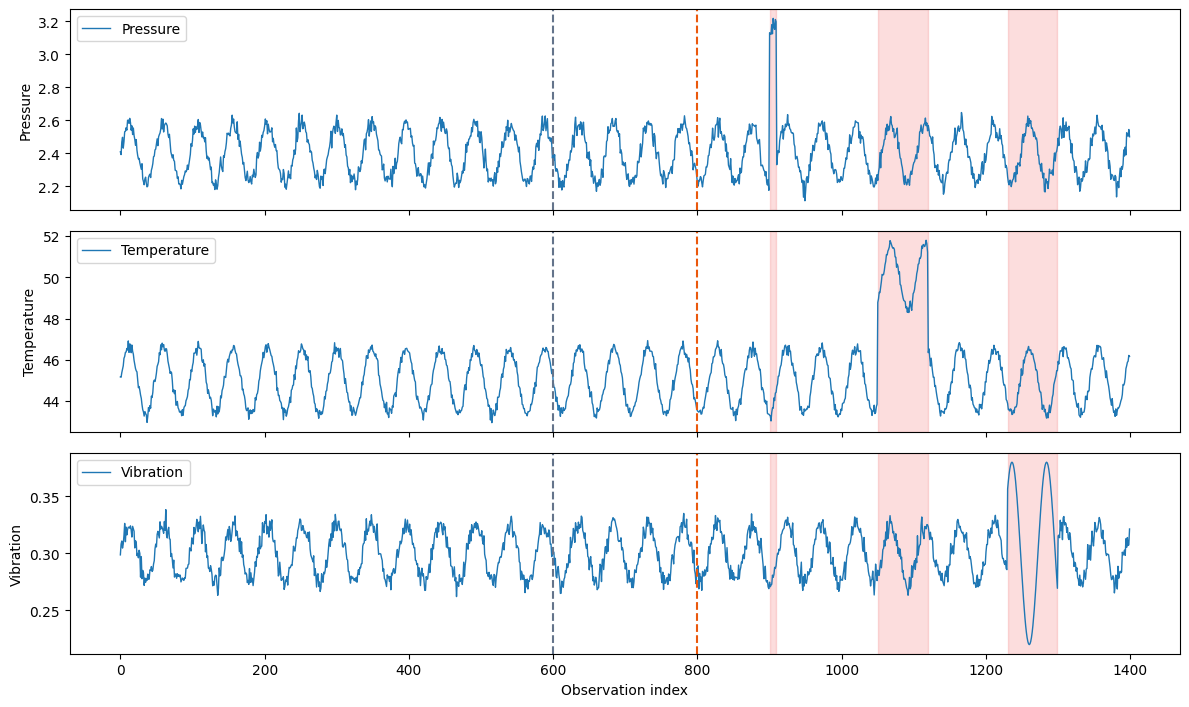

In [3]:
raw_fig, axes = plt.subplots(len(FEATURES), 1, figsize=(12, 2.4 * len(FEATURES)),
                             sharex=True, squeeze=False)
for ax, feature in zip(axes.ravel(), FEATURES):
    ax.plot(frame.index, sensor_frame[feature], lw=1, label=feature)
    if LABEL_COLUMN is not None:
        ax.fill_between(frame.index, 0, 1, where=frame[LABEL_COLUMN].eq(1),
                        transform=ax.get_xaxis_transform(), color="#ef4444", alpha=0.18)
    ax.axvline(TRAIN_END, color="#64748b", ls="--")
    ax.axvline(CALIB_END, color="#ea580c", ls="--")
    ax.set(ylabel=feature)
    ax.legend(loc="upper left")
axes.ravel()[-1].set_xlabel("Observation index")
raw_fig.tight_layout()
plt.show()

- 센서마다 축을 나누어 서로 다른 단위와 크기의 파형을 확인함
- 두 점선은 학습·보정·시험 구간의 경계이며, 붉은 배경은 정답이 제공된 경우의 이상 구간임
- 기본 예제에서는 압력·온도·진동에 서로 다른 변화가 나타나는지 확인함
- 자신의 자료에서는 정상 구간에 운전모드 변화나 이상이 섞이지 않았는지 함께 검토함

## 3) 전처리

- 입력 센서와 정답을 분리하고 학습 → 정상 보정 → 시험 순서로 데이터를 나눔
- 시각 열이 있으면 파싱·중복·역순을 검사하며, 행을 자동 정렬하거나 결측값을 삭제하지 않음
- 센서의 수집 간격과 단위가 일관적인지 확인함. 일정하지 않은 수집 간격의 재표본화는 이 실습에서 자동 수행하지 않음
- 정답이 있으면 학습·보정 구간이 모두 정상 0인지 확인함. 정답이나 시각 열이 없을 때는 실제 정상 여부와 시간순을 사용자가 확인해야 함
- 공식 모델의 전처리 방식을 사용하기 위해 외부 scaler는 만들지 않음. 각 모델의 정규화 차이는 4절에서 설명함

### Step 4: 입력 검사와 시간순 구간 분리

In [4]:
WINDOW_SIZE = 32
X = sensor_frame.to_numpy(dtype=np.float32)
assert np.isfinite(X).all(), "센서의 결측값·무한값을 확인하세요."
assert 0 < TRAIN_END < CALIB_END < len(X), "분할 경계를 확인하세요."
assert TRAIN_END >= 5 * (WINDOW_SIZE + 1), "내부 검증을 위한 정상 학습 관측이 부족합니다."
assert min(CALIB_END - TRAIN_END, len(X) - CALIB_END) > 2 * WINDOW_SIZE, "보정·시험 구간을 더 길게 지정하세요."

if TIME_COLUMN is not None:
    times = pd.to_datetime(frame[TIME_COLUMN], errors="raise")
    assert times.notna().all() and times.is_unique and times.is_monotonic_increasing, "시각의 결측·중복·시간순을 확인하세요."
labels = None
if LABEL_COLUMN is not None:
    raw_labels = frame[LABEL_COLUMN].to_numpy()
    assert np.isin(raw_labels, [0, 1]).all(), "정답은 정상 0·이상 1로 지정하세요."
    labels = raw_labels.astype(int)
    assert (labels[:CALIB_END] == 0).all(), "학습·보정에는 정상 자료를 지정하세요."

train_x, calib_x, test_x = X[:TRAIN_END], X[TRAIN_END:CALIB_END], X[CALIB_END:]
print("Normal train / calibration / test:", train_x.shape, calib_x.shape, test_x.shape)

Normal train / calibration / test: (600, 3) (200, 3) (600, 3)


- `X`는 `(관측 수, 센서 수)`의 float32 배열이며, 센서 개수는 사용자 설정에 따라 결정됨
- 정답은 정수 변환 전에 0·1 여부를 검사하여 잘못된 라벨을 그대로 정상으로 바꾸지 않도록 함
- 기본 예제는 학습 `(600, 3)`, 보정 `(200, 3)`, 시험 `(600, 3)`으로 분리됨
- 보정·시험은 양끝 경계의 영향을 제외하고도 평가 관측이 남도록 길이를 확인함
- 길이 검사는 실행에 필요한 최소 조건임. 임계값 보정을 위해 정상 운전의 여러 주기와 변동을 포함하는 충분한 자료를 확보함
- `LABEL_COLUMN=None`이면 점수·경보 계산은 계속 수행하며, 정답 기반 지표 계산만 생략함

### Step 5: 모델에 전달할 연속 관측 샘플 확인

Training array: (600, 3) | One 32-observation sample: (32, 3)


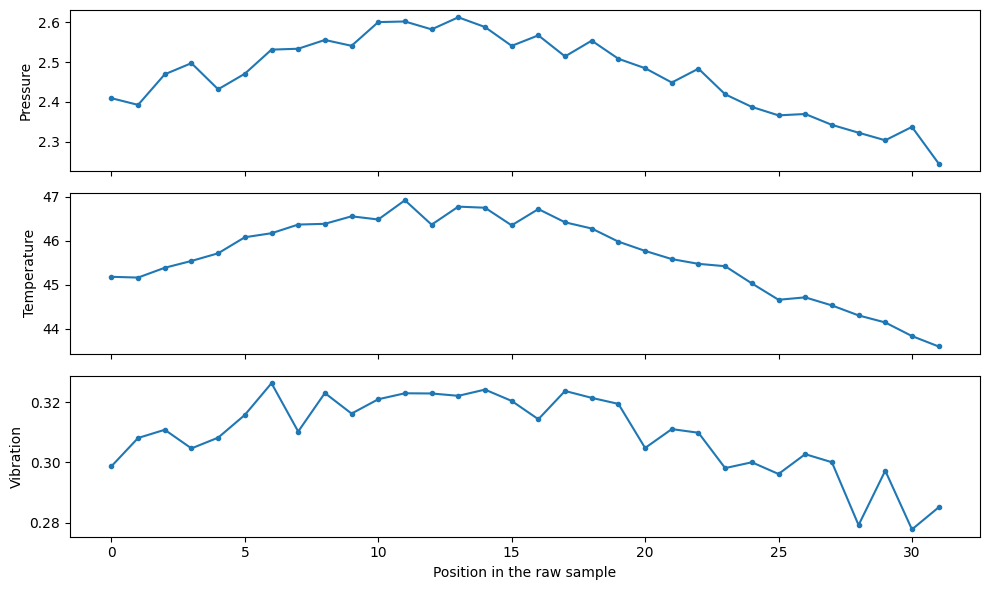

In [5]:
sample = train_x[:WINDOW_SIZE]
print("Training array:", train_x.shape, "| One 32-observation sample:", sample.shape)
sample_fig, axes = plt.subplots(len(FEATURES), 1, figsize=(10, 2 * len(FEATURES)),
                                sharex=True, squeeze=False)
for ax, feature, column in zip(axes.ravel(), FEATURES, range(len(FEATURES))):
    ax.plot(np.arange(WINDOW_SIZE), sample[:, column], "o-", ms=3)
    ax.set(ylabel=feature)
axes.ravel()[-1].set_xlabel("Position in the raw sample")
sample_fig.tight_layout()
plt.show()

- 세 모델의 `fit()`에는 윈도로 미리 변환한 텐서가 아니라 원래 2차원 `train_x`를 전달함
- 그림은 학습 배열의 앞 32개 관측을 보여주는 원본 샘플임. 기본 예제에서는 `(32, 3)` 형상임
- 실제 표준화와 내부 윈도 구성은 각 공식 모델이 수행함. 여기서는 입력 열과 시간순 분할을 확인함

## 4) 모델개발

### 4-1) 모델구조선정

- 예측·복원·대조 기반 방법을 각각 대표하는 TSB-AD의 공식 모델을 그대로 사용함
- 모델 구조나 학습 반복문을 직접 작성하지 않고, 모델 생성과 `fit()`·`decision_function()` 호출로 적용함

| 방법 | 사용할 모델 | 학습과 이상점수의 원리 |
|---|---|---|
| 예측기반 | LSTMAD | 과거 32개로 다음 1개를 예측하고 실제값과의 MSE를 사용함 |
| 복원기반 | USAD | 정상 윈도를 압축·복원하는 오토인코더 계열이며, 두 복원 경로의 오차를 조합함 |
| 대조기반 | PaAno_PAI | 정상 패치의 표현을 학습하고 가까운 정상 참조와의 평균 코사인 거리를 사용함 |

- USAD는 배운 AutoEncoder를 확장한 모델이며, 이번에는 TSB-AD의 제공 구현을 직접 호출함
- PaAno는 `public_pai` 경로를 선택함. 1D CNN으로 정상 패치를 표현하고 Triplet·초기 pretext 학습을 수행하며, 추론에서는 가까운 정상 참조 3개와의 거리를 사용함
- 세 모델의 내부 정규화와 점수 집계 방식은 동일하지 않으므로, 같은 데이터에서 각 공식 API가 어떤 결과를 반환하는지 확인하는 실습으로 해석함

| 모델 | 이 실습의 정규화 | 원형 점수의 시간 처리 |
|---|---|---|
| LSTMAD | 내부 학습·검증·보정·시험 배열마다 따로 표준화함 | 과거 입력으로 다음 시점을 예측하며 앞 32개는 채움 점수임 |
| USAD | 내부 학습·검증·보정·시험 배열마다 따로 표준화함 | 윈도 오차를 중심 시점에 배치하고 양끝을 채움 |
| PaAno_PAI | `train_zscore=True`로 정상 학습 통계를 다른 구간에 재사용함 | 각 시점에 겹치는 패치들의 거리를 평균함 |

- USAD와 PaAno의 원형 점수에는 해당 시점 이후의 관측도 반영됨. 이번 비교는 전체 구간을 받은 뒤 수행하는 **오프라인 탐지**이며 실시간 최초 경보 지연으로 해석하지 않음
- LSTMAD도 시험 배열 전체의 평균·표준편차를 사용하므로, 전처리까지 포함하면 미래 관측을 사용하지 않는 실시간 구성은 아님

### Step 6: 공식 소스 준비와 세 모델 불러오기

In [6]:
import io
import sys
import zipfile
from pathlib import PurePosixPath
import requests
import torch

TSB_SHA = "303dffbfc11612995b17b06633f8c9d0ea0e38e5"
TSB_SOURCE_ROOT = LAB_DIR / ".cache" / f"TSB-AD-{TSB_SHA}"
if not (TSB_SOURCE_ROOT / "TSB_AD/models/PaAno_PAI.py").is_file():
    response = requests.get(f"https://api.github.com/repos/thedatumorg/TSB-AD/zipball/{TSB_SHA}",
                            timeout=(15, 90))
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        prefix = archive.namelist()[0].split("/")[0]
        for item in archive.infolist():
            relative = PurePosixPath(item.filename).relative_to(prefix)
            if item.is_dir() or not relative.parts:
                continue
            target = TSB_SOURCE_ROOT.joinpath(*relative.parts)
            assert target.resolve().is_relative_to(TSB_SOURCE_ROOT.resolve())
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(item))
sys.path.insert(0, str(TSB_SOURCE_ROOT))
from TSB_AD.models.LSTMAD import LSTMAD
from TSB_AD.models.USAD import USAD
from TSB_AD.models.PaAno_PAI import PaAno_PAI

torch.set_num_threads(2)
np.random.seed(42)
torch.manual_seed(42)
print("Official model source:", TSB_SOURCE_ROOT)

Official model source: /home/chohi/PythonProjectLLM/AI_EDU/13w/.cache/TSB-AD-303dffbfc11612995b17b06633f8c9d0ea0e38e5


- PaAno까지 포함된 고정 소스를 내려받아 세 공식 모델을 직접 불러옴. 이미 받은 소스는 재사용함
- Python 패키지 환경은 기초와 동일하며, 이번 검증은 CPU와 난수 시드 42를 사용함

### Step 7: 공식 모델 생성과 학습 설정

In [7]:
import numpy as np
np.Inf = np.inf

paano_batch = 32
train_patches = len(train_x) - WINDOW_SIZE + 1
while train_patches % paano_batch == 1:
    paano_batch -= 1

models = {
    "LSTMAD": LSTMAD(window_size=WINDOW_SIZE, pred_len=1, feats=train_x.shape[1],
                      epochs=10, batch_size=64, validation_size=0.2),
    "USAD": USAD(win_size=WINDOW_SIZE, feats=train_x.shape[1],
                  epochs=10, batch_size=64, validation_size=0.2),
    "PaAno": PaAno_PAI(HP={
        "score_recipe": "public_pai", "patch_size": WINDOW_SIZE, "stride": 1,
        "num_iters": 40, "batch_size": paano_batch, "embed_dim": 16, "projection_dim": 32,
        "pretext_step": 1, "top_k": 3, "train_zscore": True, "use_revin": False,
        "device": "cuda", "seed": 42,
    }),
}
print("Selected models:", list(models), "| PaAno batch size:", paano_batch)

----- Using GPU 1 -----
self.device:  cuda:1
----- Using GPU 0 -----
Selected models: ['LSTMAD', 'USAD', 'PaAno'] | PaAno batch size: 32


- LSTMAD와 USAD는 최대 10 epoch와 내부 검증 비율 20%를 지정함
- PaAno의 `num_iters=40`은 epoch가 아닌 배치 업데이트 횟수임. `paano_batch`는 마지막 배치가 1개가 되지 않도록 조정함
- `train_zscore=True`로 학습 기준 표준화를 사용하고, `use_revin=False`로 패치마다 평균 수준을 제거하는 처리는 사용하지 않음
- 모델별 학습 방식과 횟수가 다르므로 학습 예산을 같게 맞춘 벤치마크가 아니라, 같은 사용자 데이터에 세 API를 적용하는 예제로 사용함

### 4-2) 모델학습

- 세 모델에 같은 정상 학습 배열을 전달하고, 학습에 사용하지 않은 보정·시험 배열의 점수를 계산함
- `fit()`을 모델 생성과 분리하여 호출함. 일부 모델은 `fit()`의 반환값이 없으므로 연결 호출하지 않음
- 기본 API의 경계 처리를 그대로 두고, 비교할 때는 보정·시험의 양끝 32개를 공통으로 제외함
- 이 제외 규칙은 채움 점수와 패치 경계 영향을 줄이기 위한 것이며, 모델별 점수 집계의 의미를 같게 바꾸는 처리는 아님

### Step 8: 모델 학습과 보정·시험 점수 계산

In [8]:
results = {}
for name, model in models.items():
    print("Training:", name)
    model.fit(train_x)
    calibration_score = np.asarray(model.decision_function(calib_x), dtype=float).reshape(-1)
    test_score = np.asarray(model.decision_function(test_x), dtype=float).reshape(-1)
    assert len(calibration_score) == len(calib_x) and len(test_score) == len(test_x)
    assert np.isfinite(calibration_score).all() and np.isfinite(test_score).all()
    results[name] = {"calibration_score": calibration_score[WINDOW_SIZE:-WINDOW_SIZE],
                     "score": test_score[WINDOW_SIZE:-WINDOW_SIZE]}
print("Evaluated calibration / test:", len(results["LSTMAD"]["calibration_score"]),
      len(results["LSTMAD"]["score"]))

Training: LSTMAD


Validation Epoch [9/10]: 100%|██████████| 2/2 [00:00<00:00, 769.60it/s, avg_loss=0.694, loss=0.636]


torch.Size([]) torch.Size([])


Testing: : 100%|██████████| 9/9 [00:00<00:00, 1043.62it/s]


Training: USAD


100%|██████████| 9/9 [00:00<00:00, 1531.95it/s]


Training: PaAno
Evaluated calibration / test: 136 536


- `fit(train_x)`과 `decision_function()`만으로 세 모델의 학습·점수 계산을 실행함
- 각 모델이 구간 길이와 같은 수의 유한 점수를 반환했는지 확인한 뒤 같은 행 범위를 선택함
- 기본 예제의 보정 200개는 136개, 시험 600개는 536개 관측으로 평가함
- LSTMAD의 앞쪽 채움, USAD의 양끝 채움은 제외되며, PaAno는 양끝의 패치 포함 횟수가 적은 영역을 제외함

## 5) 실험 분석

- 각 모델의 정상 보정 점수에서 별도로 99% 분위수 임계값을 구함. 모델별 점수 척도가 다르므로 같은 숫자의 임계값을 공통 적용하지 않음
- 정답이 있으면 같은 시험 행에 대해 정확도·F1-Score·AUROC와 오경보 비율을 비교함
- 정답이 없으면 점수·경보·경보 비율을 확인하며, 정답을 임의로 만들어 지표를 계산하지 않음

### Step 9: 정상 보정 임계값과 평가 지표 계산

In [9]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

evaluation_rows = np.arange(CALIB_END + WINDOW_SIZE, len(X) - WINDOW_SIZE)
y_eval = labels[evaluation_rows] if labels is not None else None
metric_rows = []
for name, result in results.items():
    threshold = float(np.quantile(result["calibration_score"], 0.99))
    prediction = (result["score"] > threshold).astype(int)
    result.update({"threshold": threshold, "prediction": prediction})
    row = {"Model": name, "Threshold": threshold, "Alarm_ratio": float(prediction.mean())}
    if y_eval is not None:
        normal = y_eval == 0
        row.update({"Accuracy": accuracy_score(y_eval, prediction),
                    "F1-Score": f1_score(y_eval, prediction, zero_division=0),
                    "AUROC": roc_auc_score(y_eval, result["score"]) if len(np.unique(y_eval)) == 2 else np.nan,
                    "FPR": float(prediction[normal].mean()) if normal.any() else np.nan})
    metric_rows.append(row)
if y_eval is not None:
    baseline = np.zeros_like(y_eval)
    metric_rows.append({"Model": "Always normal", "Threshold": np.nan, "Alarm_ratio": 0.0,
                        "Accuracy": accuracy_score(y_eval, baseline),
                        "F1-Score": f1_score(y_eval, baseline, zero_division=0),
                        "AUROC": 0.5 if len(np.unique(y_eval)) == 2 else np.nan,
                        "FPR": 0.0 if (y_eval == 0).any() else np.nan})
comparison = pd.DataFrame(metric_rows)
display(comparison.round(4))

,Model,Threshold,Alarm_ratio,Accuracy,F1-Score,AUROC,FPR
0,LSTMAD,1.7716,0.1679,0.8881,0.7500,0.9236,0.0000
1,USAD,1.6995,0.2108,0.8526,0.6996,0.9342,0.0544
2,PaAno,0.0062,0.6660,0.6138,0.5917,0.9843,0.5363
3,Always normal,NaN,0.0000,0.7201,0.0000,0.5000,0.0000


- 정확도는 전체 정분류 비율, F1은 이상 1을 양성으로 두는 정밀도·재현율의 조화평균임
- AUROC는 이진 경보가 아닌 연속 이상점수로 계산하며 0.5는 무작위 기준임
- `FPR`은 시험 정상 중 경보 비율, `Alarm_ratio`는 전체 시험 관측 중 경보 비율임
- 항상 정상 기준선과 비교하여 정확도만 높게 보이는 상황을 확인함. 시험 정답이 한 종류뿐이면 AUROC는 계산하지 않음
- 정상 보정 136개로 구한 99% 분위수가 새 시험 자료의 오경보율 1%를 보장하지는 않음

### Step 10: 세 모델의 점수와 경보 위치 비교

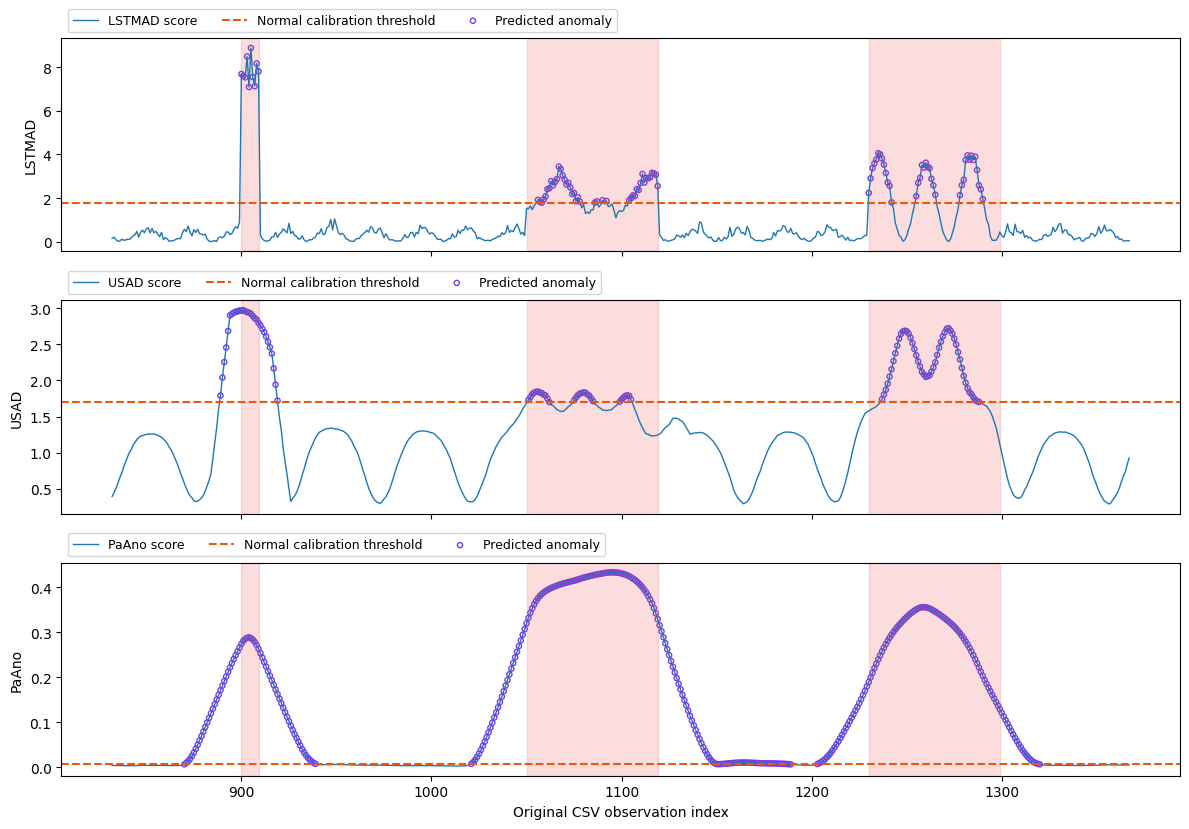

In [10]:
score_fig, axes = plt.subplots(len(results), 1, figsize=(12, 2.8 * len(results)), sharex=True)
for ax, (name, result) in zip(np.atleast_1d(axes), results.items()):
    ax.plot(evaluation_rows, result["score"], lw=1, label=f"{name} score")
    ax.axhline(result["threshold"], color="#ea580c", ls="--", label="Normal calibration threshold")
    alarm = result["prediction"] == 1
    ax.scatter(evaluation_rows[alarm], result["score"][alarm], s=14,
                facecolors="none", edgecolors="#7c3aed", label="Predicted anomaly")
    if y_eval is not None:
        ax.fill_between(evaluation_rows, 0, 1, where=y_eval == 1,
                        transform=ax.get_xaxis_transform(), color="#ef4444", alpha=0.18)
    ax.set(ylabel=name)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=3, fontsize=9)
np.atleast_1d(axes)[-1].set_xlabel("Original CSV observation index")
score_fig.tight_layout()
plt.show()

- 모델마다 점수 축을 따로 두고, 자신의 정상 보정 임계값과 경보 위치를 함께 표시함
- 붉은 정답 구간 안에서 경보가 유지되는지, 구간 밖 정상에서 오경보가 발생하는지 확인함
- 원점수의 크기 자체로 우열을 비교하지 않고, 이상 유형별 반응과 지표를 함께 해석함
- 원형 모델의 윈도 집계에 미래 관측이 포함될 수 있으므로 경보 위치를 실시간 탐지 지연으로 해석하지 않음

### Step 11: 지표 또는 경보 비율을 시각화하여 비교

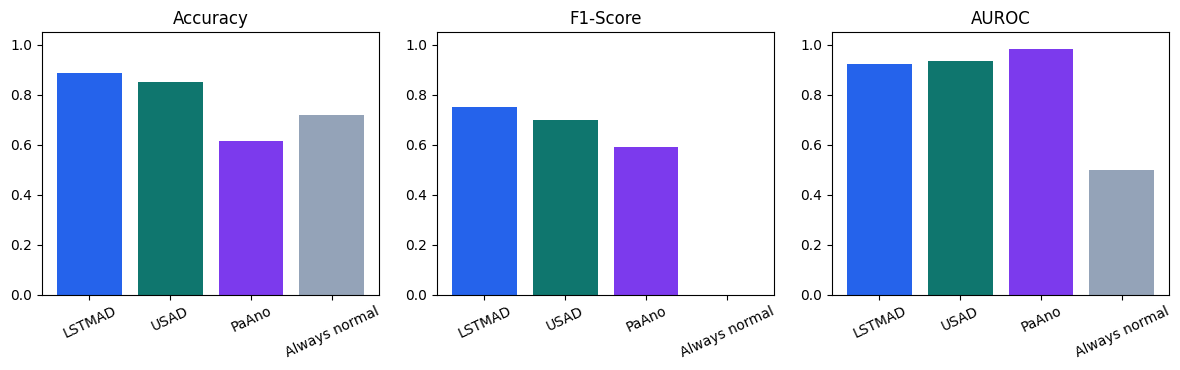

In [11]:
if y_eval is not None:
    metric_fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, metric in zip(axes, ["Accuracy", "F1-Score", "AUROC"]):
        ax.bar(comparison["Model"], comparison[metric], color=["#2563eb", "#0f766e", "#7c3aed", "#94a3b8"])
        ax.set(title=metric, ylim=(0, 1.05))
        ax.tick_params(axis="x", rotation=25)
else:
    metric_fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(comparison["Model"], comparison["Alarm_ratio"], color=["#2563eb", "#0f766e", "#7c3aed"])
    ax.set(title="Alarm ratio without ground truth", ylim=(0, 1.05))
metric_fig.tight_layout()
plt.show()

- 정답이 있으면 정확도·F1·AUROC를 항상 정상 기준선과 함께 비교함
- 정확도가 높더라도 F1이 낮으면 오경보·미탐을 확인하고, AUROC와 현재 임계값의 경보를 구분하여 해석함
- 정답이 없을 때의 경보 비율은 성능 지표가 아님. 실제 경보 구간을 운영 기록과 대조하는 데 사용함

**기본 예제 실행 결과 해석**

- 아래 수치는 기본 합성 CSV·CPU·시드 42로 실행한 결과임. 자신의 CSV나 실행 환경으로 바꾸면 출력 표의 수치를 기준으로 다시 해석함
- 평가 536개 중 이상은 150개, 정상은 386개임. 항상 정상으로 판단해도 정확도는 약 0.7201이지만 F1은 0임
- LSTMAD의 정확도는 약 0.8881, F1은 0.7500, AUROC는 0.9236임. 이상 150개 중 90개에 경보를 내고, 정상 386개에서는 오경보가 없었음. 정상 오경보가 적더라도 미탐 60개가 남아 있음을 확인함
- USAD의 정확도는 약 0.8526, F1은 0.6996, AUROC는 0.9342임. 이상 92개를 찾았지만 정상 21개에도 경보가 발생함. LSTMAD보다 AUROC가 높더라도 현재 임계값의 F1은 낮을 수 있음을 확인함
- PaAno의 AUROC는 약 0.9912로 점수의 순위 구분은 우수하지만, F1은 약 0.6098이고 FPR은 약 49.74%임. 이상 150개를 모두 찾는 대신 정상 192개에도 경보를 내어, 높은 AUROC가 현재 임계값의 적은 오경보를 보장하지 않음을 확인함
- PaAno의 중첩 패치 점수는 이상 전후 정상에도 확산되어 나타날 수 있음. 시험 정답에 맞춰 임계값을 다시 고르지 않고, 충분한 정상 보정 자료와 별도의 검증 자료로 경보 조건을 검토함
- 이 결과는 한 합성 예제에서의 비교임. LSTMAD·USAD·PaAno나 예측·복원·대조 방식 전체의 일반적인 우열을 뜻하지 않음

**히스토그램을 이용한 임계값 조정**

- 정상·이상 점수의 히스토그램 경계 중 **F1이 가장 높은 임계값**을 선택하고, 정상 보정 99% 분위수 결과와 비교함
- 시험 정답을 사용하는 사후 분석임. 실제 운영에서는 별도 검증 자료로 임계값을 정한 뒤 미사용 시험 자료로 평가함

### Step 11-1: 히스토그램으로 정상·이상을 구분하는 임계값 설정

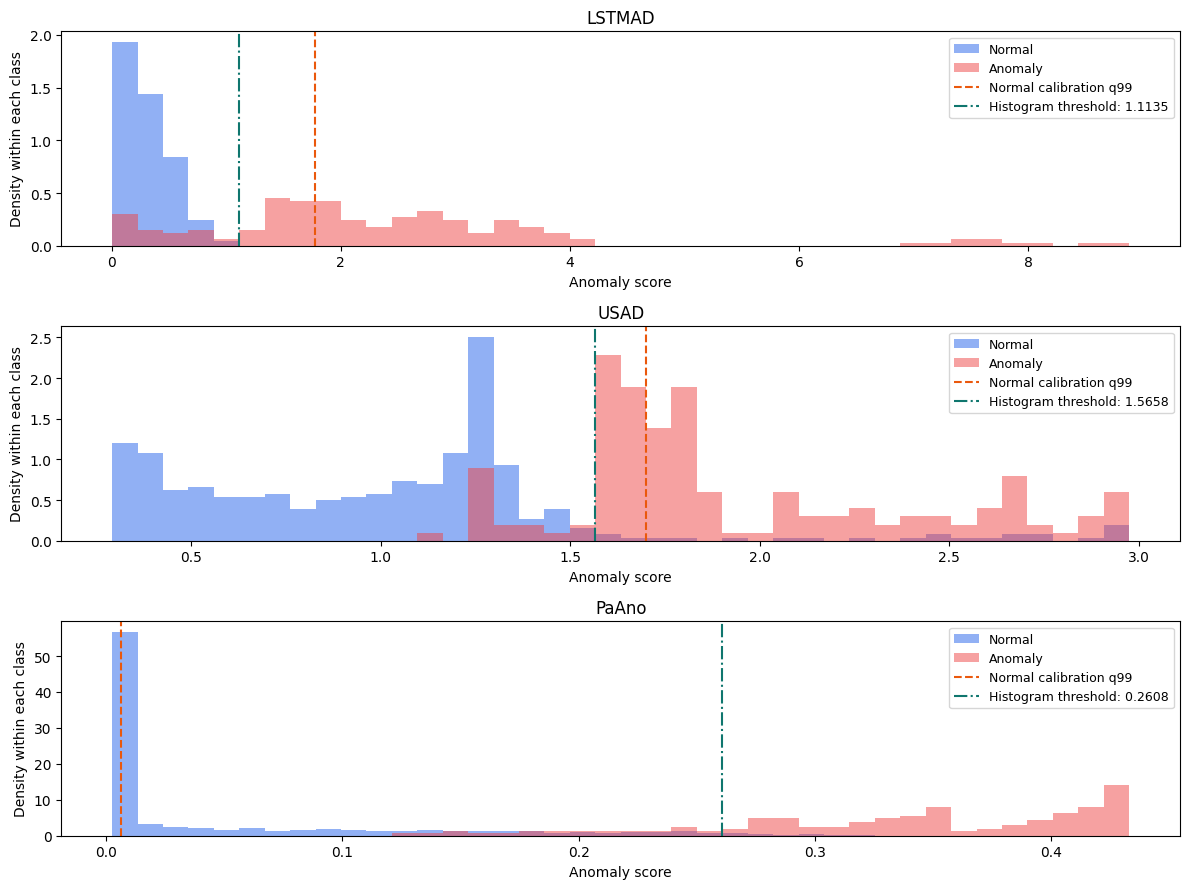

In [12]:
hist_ready = y_eval is not None and np.unique(y_eval).size == 2
hist_results = {}
hist_fig, adjusted_fig = None, None
if hist_ready:
    hist_fig, hist_axes = plt.subplots(len(results), 1, figsize=(12, 3 * len(results)), squeeze=False)
    for hist_ax, (hist_name, hist_result) in zip(hist_axes.ravel(), results.items()):
        hist_score = np.asarray(hist_result["score"])
        hist_bins = np.histogram_bin_edges(hist_score, bins=40)
        hist_candidates = np.r_[np.nextafter(hist_bins[0], -np.inf), hist_bins]
        hist_f1 = [f1_score(y_eval, hist_score > threshold, zero_division=0) for threshold in hist_candidates]
        hist_threshold = float(hist_candidates[np.argmax(hist_f1)])
        hist_results[hist_name] = {"threshold": hist_threshold, "prediction": (hist_score > hist_threshold).astype(int)}
        hist_ax.hist(hist_score[y_eval == 0], bins=hist_bins, density=True, alpha=0.5, color="#2563eb", label="Normal")
        hist_ax.hist(hist_score[y_eval == 1], bins=hist_bins, density=True, alpha=0.5, color="#ef4444", label="Anomaly")
        hist_ax.axvline(hist_result["threshold"], color="#ea580c", ls="--", label="Normal calibration q99")
        hist_ax.axvline(hist_threshold, color="#0f766e", ls="-.", label=f"Histogram threshold: {hist_threshold:.4f}")
        hist_ax.set(title=hist_name, xlabel="Anomaly score", ylabel="Density within each class")
        hist_ax.legend(loc="upper right", fontsize=9)
    hist_fig.tight_layout()
    plt.show()
else:
    print("히스토그램 임계값 분석 생략: 정상·이상 정답이 모두 필요함")

- 파란색은 정상, 붉은색은 이상 점수 분포임. 같은 모델에서는 두 분포에 동일한 40개 구간을 사용함
- 구간 경계를 임계값 후보로 두고, `점수 > 임계값`으로 구분했을 때 F1이 가장 높은 후보를 선택함
- 주황 점선은 기존 정상 보정 99% 분위수, 초록 선은 히스토그램으로 조정한 임계값임
- `density=True`는 각 클래스의 면적을 1로 맞추는 표시 방식임. F1 계산에는 실제 정상·이상 표본 비율을 그대로 사용함
- 선택값은 **40개 구간 경계 후보 중 최적값**임. 구간 수가 달라지면 값이 달라질 수 있으며, 모든 실수 임계값을 정밀 탐색한 값과 구분함

### Step 11-2: 정상 보정 99% 분위수와 성능·경보 위치 비교

,Model,Threshold method,Threshold,Accuracy,F1-Score,AUROC,FPR
0,LSTMAD,Normal q99,1.7716,0.8881,0.7500,0.9236,0.0000
1,LSTMAD,Histogram adjusted,1.1135,0.9515,0.9051,0.9236,0.0000
2,USAD,Normal q99,1.6995,0.8526,0.6996,0.9342,0.0544
3,USAD,Histogram adjusted,1.5658,0.9235,0.8664,0.9342,0.0622
4,PaAno,Normal q99,0.0062,0.6138,0.5917,0.9843,0.5363
5,PaAno,Histogram adjusted,0.2608,0.9366,0.8811,0.9843,0.0259


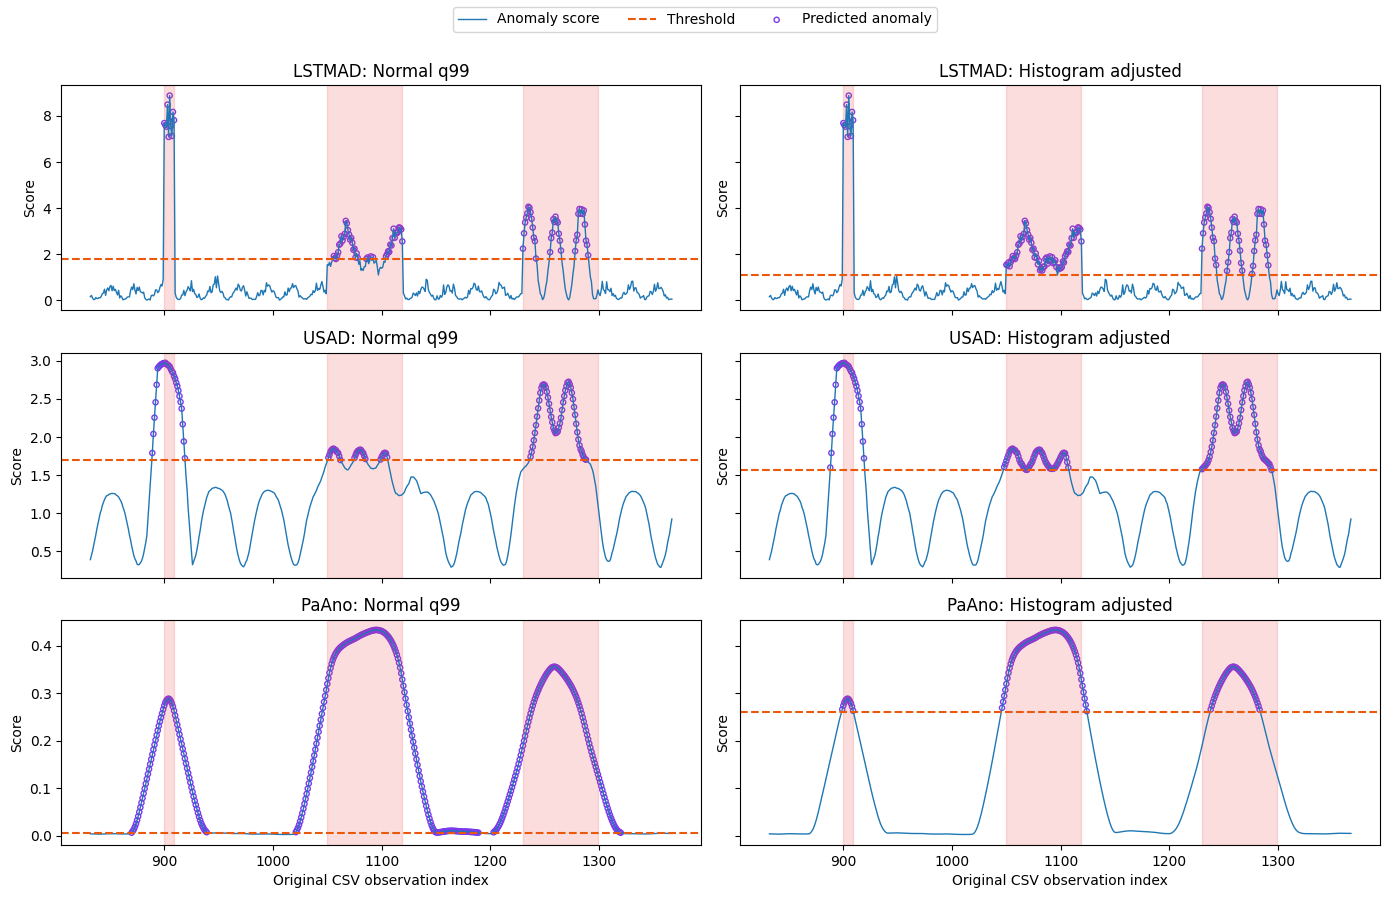

In [13]:
if hist_ready:
    adjusted_rows = []
    adjusted_fig, adjusted_axes = plt.subplots(len(results), 2, figsize=(14, 3 * len(results)), sharex=True, sharey="row", squeeze=False)
    for adjusted_row, (adjusted_name, adjusted_result) in enumerate(results.items()):
        adjusted_cases = [
            ("Normal q99", adjusted_result["threshold"], adjusted_result["prediction"]),
            ("Histogram adjusted", hist_results[adjusted_name]["threshold"], hist_results[adjusted_name]["prediction"]),
        ]
        for adjusted_col, (adjusted_method, adjusted_threshold, adjusted_prediction) in enumerate(adjusted_cases):
            adjusted_rows.append({"Model": adjusted_name, "Threshold method": adjusted_method, "Threshold": adjusted_threshold,
                "Accuracy": accuracy_score(y_eval, adjusted_prediction), "F1-Score": f1_score(y_eval, adjusted_prediction, zero_division=0),
                "AUROC": roc_auc_score(y_eval, adjusted_result["score"]), "FPR": float(np.mean(adjusted_prediction[y_eval == 0]))})
            adjusted_ax = adjusted_axes[adjusted_row, adjusted_col]
            adjusted_ax.plot(evaluation_rows, adjusted_result["score"], lw=1, label="Anomaly score")
            adjusted_ax.axhline(adjusted_threshold, color="#ea580c", ls="--", label="Threshold")
            adjusted_alarm = adjusted_prediction == 1
            adjusted_ax.scatter(evaluation_rows[adjusted_alarm], adjusted_result["score"][adjusted_alarm], s=14,
                                facecolors="none", edgecolors="#7c3aed", label="Predicted anomaly")
            adjusted_ax.fill_between(evaluation_rows, 0, 1, where=y_eval == 1,
                                     transform=adjusted_ax.get_xaxis_transform(), color="#ef4444", alpha=0.18)
            adjusted_ax.set(title=f"{adjusted_name}: {adjusted_method}", ylabel="Score")
    adjusted_comparison = pd.DataFrame(adjusted_rows)
    display(adjusted_comparison.round(4))
    for adjusted_ax in adjusted_axes[-1]:
        adjusted_ax.set_xlabel("Original CSV observation index")
    adjusted_fig.legend(*adjusted_axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3)
    adjusted_fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

- 표는 같은 모델·시험 점수에 대해 기존 임계값과 조정 임계값의 정확도·F1·AUROC·FPR을 비교함
- 왼쪽은 기존 99% 분위수 경보, 오른쪽은 히스토그램 임계값의 경보임. 같은 행의 점수 축을 공유하여 경보 위치와 범위를 직접 비교함
- 붉은 배경은 정답 이상 구간, 보라색 원은 예측 경보임. 정상 구간의 오경보와 이상 구간의 미탐이 어떻게 바뀌는지 확인함
- 점수와 모델은 같으므로 AUROC는 변하지 않음. 임계값 조정으로 바뀌는 경보 성능과 구분하여 읽음

**기본 합성 예제의 결과 해석**

| 모델 | 기존 F1 | 히스토그램 임계값 F1 |
|---|---:|---:|
| LSTMAD | 0.7500 | 0.9051 |
| USAD | 0.6996 | 0.8664 |
| PaAno | 0.6098 | 0.9221 |

- PaAno는 임계값을 약 0.005315에서 0.246651로 높이면 정상 구간의 경보가 크게 줄어듦. 이상 150개 중 142개를 탐지하고 정상 386개 중 16개에 경보를 냄
- PaAno의 정확도는 약 0.9552, FPR은 약 0.0415임. 경보 위치 그림에서 구간 밖 오경보 감소와 함께 미탐 8개가 남는 점도 확인함
- 위 수치는 기본 합성 CSV·시드 42의 사후 결과임. 데이터를 바꾼 경우에는 실행한 표와 그림으로 다시 해석함

### Step 12: 사용자 데이터의 점수·경보·설정 저장

In [14]:
import json

OUTPUT_DIR = LAB_DIR / "results/00_tsb_ad_advanced"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output = frame.iloc[evaluation_rows][FEATURES].copy()
output.insert(0, "observation", evaluation_rows)
if TIME_COLUMN is not None:
    output[TIME_COLUMN] = frame.iloc[evaluation_rows][TIME_COLUMN].to_numpy()
if y_eval is not None:
    output["Label"] = y_eval
for name, result in results.items():
    output[f"{name}_score"] = result["score"]
    output[f"{name}_prediction"] = result["prediction"]
output.to_csv(OUTPUT_DIR / "custom_three_models_scores.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "custom_three_models_metrics.csv", index=False)
settings = {"source_commit": TSB_SHA, "csv_path": str(CSV_PATH), "features": FEATURES,
            "time_column": TIME_COLUMN, "label_column": LABEL_COLUMN,
            "train_end": TRAIN_END, "calibration_end": CALIB_END, "window_size": WINDOW_SIZE,
            "evaluation_rows": len(evaluation_rows), "boundary_exclusion_each_side": WINDOW_SIZE,
            "thresholds": {name: result["threshold"] for name, result in results.items()},
            "scope": "offline native-model API comparison; model-specific preprocessing and score mapping"}
(OUTPUT_DIR / "custom_three_models_settings.json").write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
for figure, filename in [(raw_fig, "custom_raw_signals.png"), (sample_fig, "custom_input_sample.png"),
                         (score_fig, "custom_three_models_scores.png"), (metric_fig, "custom_three_models_metrics.png")]:
    figure.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
print("Saved:", OUTPUT_DIR)

Saved: /home/chohi/PythonProjectLLM/AI_EDU/13w/results/00_tsb_ad_advanced


- 점수 CSV에는 같은 시험 관측의 원래 행 번호와 모델별 점수·경보를 저장함
- 지표 CSV에는 현재 비교 표를, 설정 JSON에는 센서·분할·경계 제외·임계값·평가 범위를 기록함
- 정답이 없는 경우 `Label`을 새로 만들지 않으며 점수와 경보만 저장함
- 그래프는 원본 파형·입력 샘플·모델별 점수·평가 비교를 구분하여 저장함

### Step 12-1: 임계값 조정 비교 결과 저장

In [15]:
if hist_ready:
    hist_output_dir = OUTPUT_DIR / "threshold_histogram"
    hist_output_dir.mkdir(parents=True, exist_ok=True)
    adjusted_comparison.to_csv(hist_output_dir / "comparison.csv", index=False)
    hist_fig.savefig(hist_output_dir / "score_histograms.png", dpi=150, bbox_inches="tight")
    adjusted_fig.savefig(hist_output_dir / "alarm_positions_before_after.png", dpi=150, bbox_inches="tight")
    print("Saved:", hist_output_dir)

Saved: /home/chohi/PythonProjectLLM/AI_EDU/13w/results/00_tsb_ad_advanced/threshold_histogram


- 비교 표와 두 그래프를 `threshold_histogram/`에 저장함
- 기존 정상 보정 결과는 그대로 두고, 히스토그램 임계값 결과를 별도로 확인함

## 6) 결론

- 사용자 CSV를 시간순으로 학습·정상 보정·시험 구간에 나누고, TSB-AD의 기본 제공 모델 세 가지를 직접 적용함
- 같은 `fit()`·`decision_function()` 호출로 예측오차·복원오차·정상 참조 거리를 얻고, 모델별 보정 임계값으로 경보를 생성함
- 모델의 내부 정규화와 점수 집계 방식도 결과에 영향을 줌. 이번 결과는 원형 API를 사용하는 오프라인 실습으로 해석함
- 자신의 데이터에서는 여섯 입력 설정을 바꾼 뒤 정상 구간과 센서의 수집 조건을 먼저 확인하고 같은 절차를 실행함

**확인 질문**

- 점수의 순위 구분력과 현재 임계값의 경보 결과가 다른 경우는 어떤 상황인가?

**출처와 구현 범위**

- [TSB-AD 공식 저장소](https://github.com/TheDatumOrg/TSB-AD)의 고정 소스를 직접 사용함
- [LSTMAD](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/LSTMAD.py) · [USAD](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/USAD.py) · [PaAno_PAI](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/PaAno_PAI.py)의 제공 구현을 사용하며, 별도 모델 클래스를 재정의하지 않음
- 기본 CSV는 이 노트북에서 생성한 합성 예제이며 실제 제조 벤치마크의 측정 자료가 아님
- 소스의 [Apache-2.0 라이선스](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/LICENSE)와 각 구현의 출처를 함께 확인함